In [2]:
#Importing libraries
import numpy as np
from sklearn.linear_model import LinearRegression
import pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline
import seaborn as sns
from sklearn.model_selection import train_test_split # Sklearn package's randomized data splitting function

In [3]:
#Load and review data
rdata = pd.read_csv('/content/drive/MyDrive/Colab Notebooks/auto-mpg.csv')
rdata.head()

,mpg,cylinders,displacement,horsepower,weight,acceleration,model year,origin,car name
0,18.0,8,307.0,130,3504,12.0,70,1,chevrolet chevelle malibu
1,15.0,8,350.0,165,3693,11.5,70,1,buick skylark 320
2,18.0,8,318.0,150,3436,11.0,70,1,plymouth satellite
3,16.0,8,304.0,150,3433,12.0,70,1,amc rebel sst
4,17.0,8,302.0,140,3449,10.5,70,1,ford torino


In [4]:
rdata.head()

,mpg,cylinders,displacement,horsepower,weight,acceleration,model year,origin,car name
0,18.0,8,307.0,130,3504,12.0,70,1,chevrolet chevelle malibu
1,15.0,8,350.0,165,3693,11.5,70,1,buick skylark 320
2,18.0,8,318.0,150,3436,11.0,70,1,plymouth satellite
3,16.0,8,304.0,150,3433,12.0,70,1,amc rebel sst
4,17.0,8,302.0,140,3449,10.5,70,1,ford torino


In [5]:
rdata = rdata.drop('car name', axis=1)

In [6]:
rdata['origin'] = rdata['origin'].replace({1: 'america', 2: 'europe', 3: 'asia'})
rdata.head()

,mpg,cylinders,displacement,horsepower,weight,acceleration,model year,origin
0,18.0,8,307.0,130,3504,12.0,70,america
1,15.0,8,350.0,165,3693,11.5,70,america
2,18.0,8,318.0,150,3436,11.0,70,america
3,16.0,8,304.0,150,3433,12.0,70,america
4,17.0,8,302.0,140,3449,10.5,70,america


Displaying Record Details

In [7]:
rdata.sample()

,mpg,cylinders,displacement,horsepower,weight,acceleration,model year,origin
189,15.5,8,304.0,120,3962,13.9,76,america


In [8]:
rdata.shape

(398, 8)

In [9]:
rdata.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 398 entries, 0 to 397
Data columns (total 8 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   mpg           398 non-null    float64
 1   cylinders     398 non-null    int64  
 2   displacement  398 non-null    float64
 3   horsepower    398 non-null    object 
 4   weight        398 non-null    int64  
 5   acceleration  398 non-null    float64
 6   model year    398 non-null    int64  
 7   origin        398 non-null    object 
dtypes: float64(3), int64(3), object(2)
memory usage: 25.0+ KB


In [10]:
rdata.describe()

,mpg,cylinders,displacement,weight,acceleration,model year
count,398.000000,398.000000,398.000000,398.000000,398.000000,398.000000
mean,23.514573,5.454774,193.425879,2970.424623,15.568090,76.010050
std,7.815984,1.701004,104.269838,846.841774,2.757689,3.697627
min,9.000000,3.000000,68.000000,1613.000000,8.000000,70.000000
25%,17.500000,4.000000,104.250000,2223.750000,13.825000,73.000000
50%,23.000000,4.000000,148.500000,2803.500000,15.500000,76.000000
75%,29.000000,8.000000,262.000000,3608.000000,17.175000,79.000000
max,46.600000,8.000000,455.000000,5140.000000,24.800000,82.000000


In [11]:
rdata.dtypes

,0
mpg,float64
cylinders,int64
displacement,float64
horsepower,object
weight,int64
acceleration,float64
model year,int64
origin,object


# Checking Null Values

In [12]:
rdata.isnull()

,mpg,cylinders,displacement,horsepower,weight,acceleration,model year,origin
0,False,False,False,False,False,False,False,False
1,False,False,False,False,False,False,False,False
2,False,False,False,False,False,False,False,False
3,False,False,False,False,False,False,False,False
4,False,False,False,False,False,False,False,False
...,...,...,...,...,...,...,...,...
393,False,False,False,False,False,False,False,False
394,False,False,False,False,False,False,False,False
395,False,False,False,False,False,False,False,False
396,False,False,False,False,False,False,False,False


In [13]:
rdata.isnull().sum()

,0
mpg,0
cylinders,0
displacement,0
horsepower,0
weight,0
acceleration,0
model year,0
origin,0


# Checking duplicate values

In [14]:
rdata.duplicated().sum()

np.int64(0)


# Also replacing the categorical var with actual values

In [15]:
rdata['origin'] = rdata['origin'].replace({1: 'america', 2: 'europe', 3: 'asia'})
rdata.head()

,mpg,cylinders,displacement,horsepower,weight,acceleration,model year,origin
0,18.0,8,307.0,130,3504,12.0,70,america
1,15.0,8,350.0,165,3693,11.5,70,america
2,18.0,8,318.0,150,3436,11.0,70,america
3,16.0,8,304.0,150,3433,12.0,70,america
4,17.0,8,302.0,140,3449,10.5,70,america


In [16]:
rdata = pd.get_dummies(rdata, columns=['origin'])
rdata.head()

,mpg,cylinders,displacement,horsepower,weight,acceleration,model year,origin_america,origin_asia,origin_europe
0,18.0,8,307.0,130,3504,12.0,70,True,False,False
1,15.0,8,350.0,165,3693,11.5,70,True,False,False
2,18.0,8,318.0,150,3436,11.0,70,True,False,False
3,16.0,8,304.0,150,3433,12.0,70,True,False,False
4,17.0,8,302.0,140,3449,10.5,70,True,False,False


isdigit()? on 'horsepower'

In [17]:
hpIsDigit = pd.DataFrame(rdata.horsepower.str.isdigit())  # if the string is made of digits store True else False

#print isDigit = False!
rdata[hpIsDigit['horsepower'] == False]

,mpg,cylinders,displacement,horsepower,weight,acceleration,model year,origin_america,origin_asia,origin_europe
32,25.0,4,98.0,?,2046,19.0,71,True,False,False
126,21.0,6,200.0,?,2875,17.0,74,True,False,False
330,40.9,4,85.0,?,1835,17.3,80,False,False,True
336,23.6,4,140.0,?,2905,14.3,80,True,False,False
354,34.5,4,100.0,?,2320,15.8,81,False,False,True
374,23.0,4,151.0,?,3035,20.5,82,True,False,False


Missing values have a'?''
Replace missing values with NaN

In [18]:
rdata = rdata.replace('?', np.nan)
rdata[hpIsDigit['horsepower'] == False]

,mpg,cylinders,displacement,horsepower,weight,acceleration,model year,origin_america,origin_asia,origin_europe
32,25.0,4,98.0,NaN,2046,19.0,71,True,False,False
126,21.0,6,200.0,NaN,2875,17.0,74,True,False,False
330,40.9,4,85.0,NaN,1835,17.3,80,False,False,True
336,23.6,4,140.0,NaN,2905,14.3,80,True,False,False
354,34.5,4,100.0,NaN,2320,15.8,81,False,False,True
374,23.0,4,151.0,NaN,3035,20.5,82,True,False,False


converting the horsepower column from object to float

In [19]:
rdata['horsepower'] = rdata['horsepower'].astype('float64')

In [20]:
rdata.median()

,0
mpg,23.0
cylinders,4.0
displacement,148.5
horsepower,93.5
weight,2803.5
acceleration,15.5
model year,76.0
origin_america,1.0
origin_asia,0.0
origin_europe,0.0


BiVariate Plots

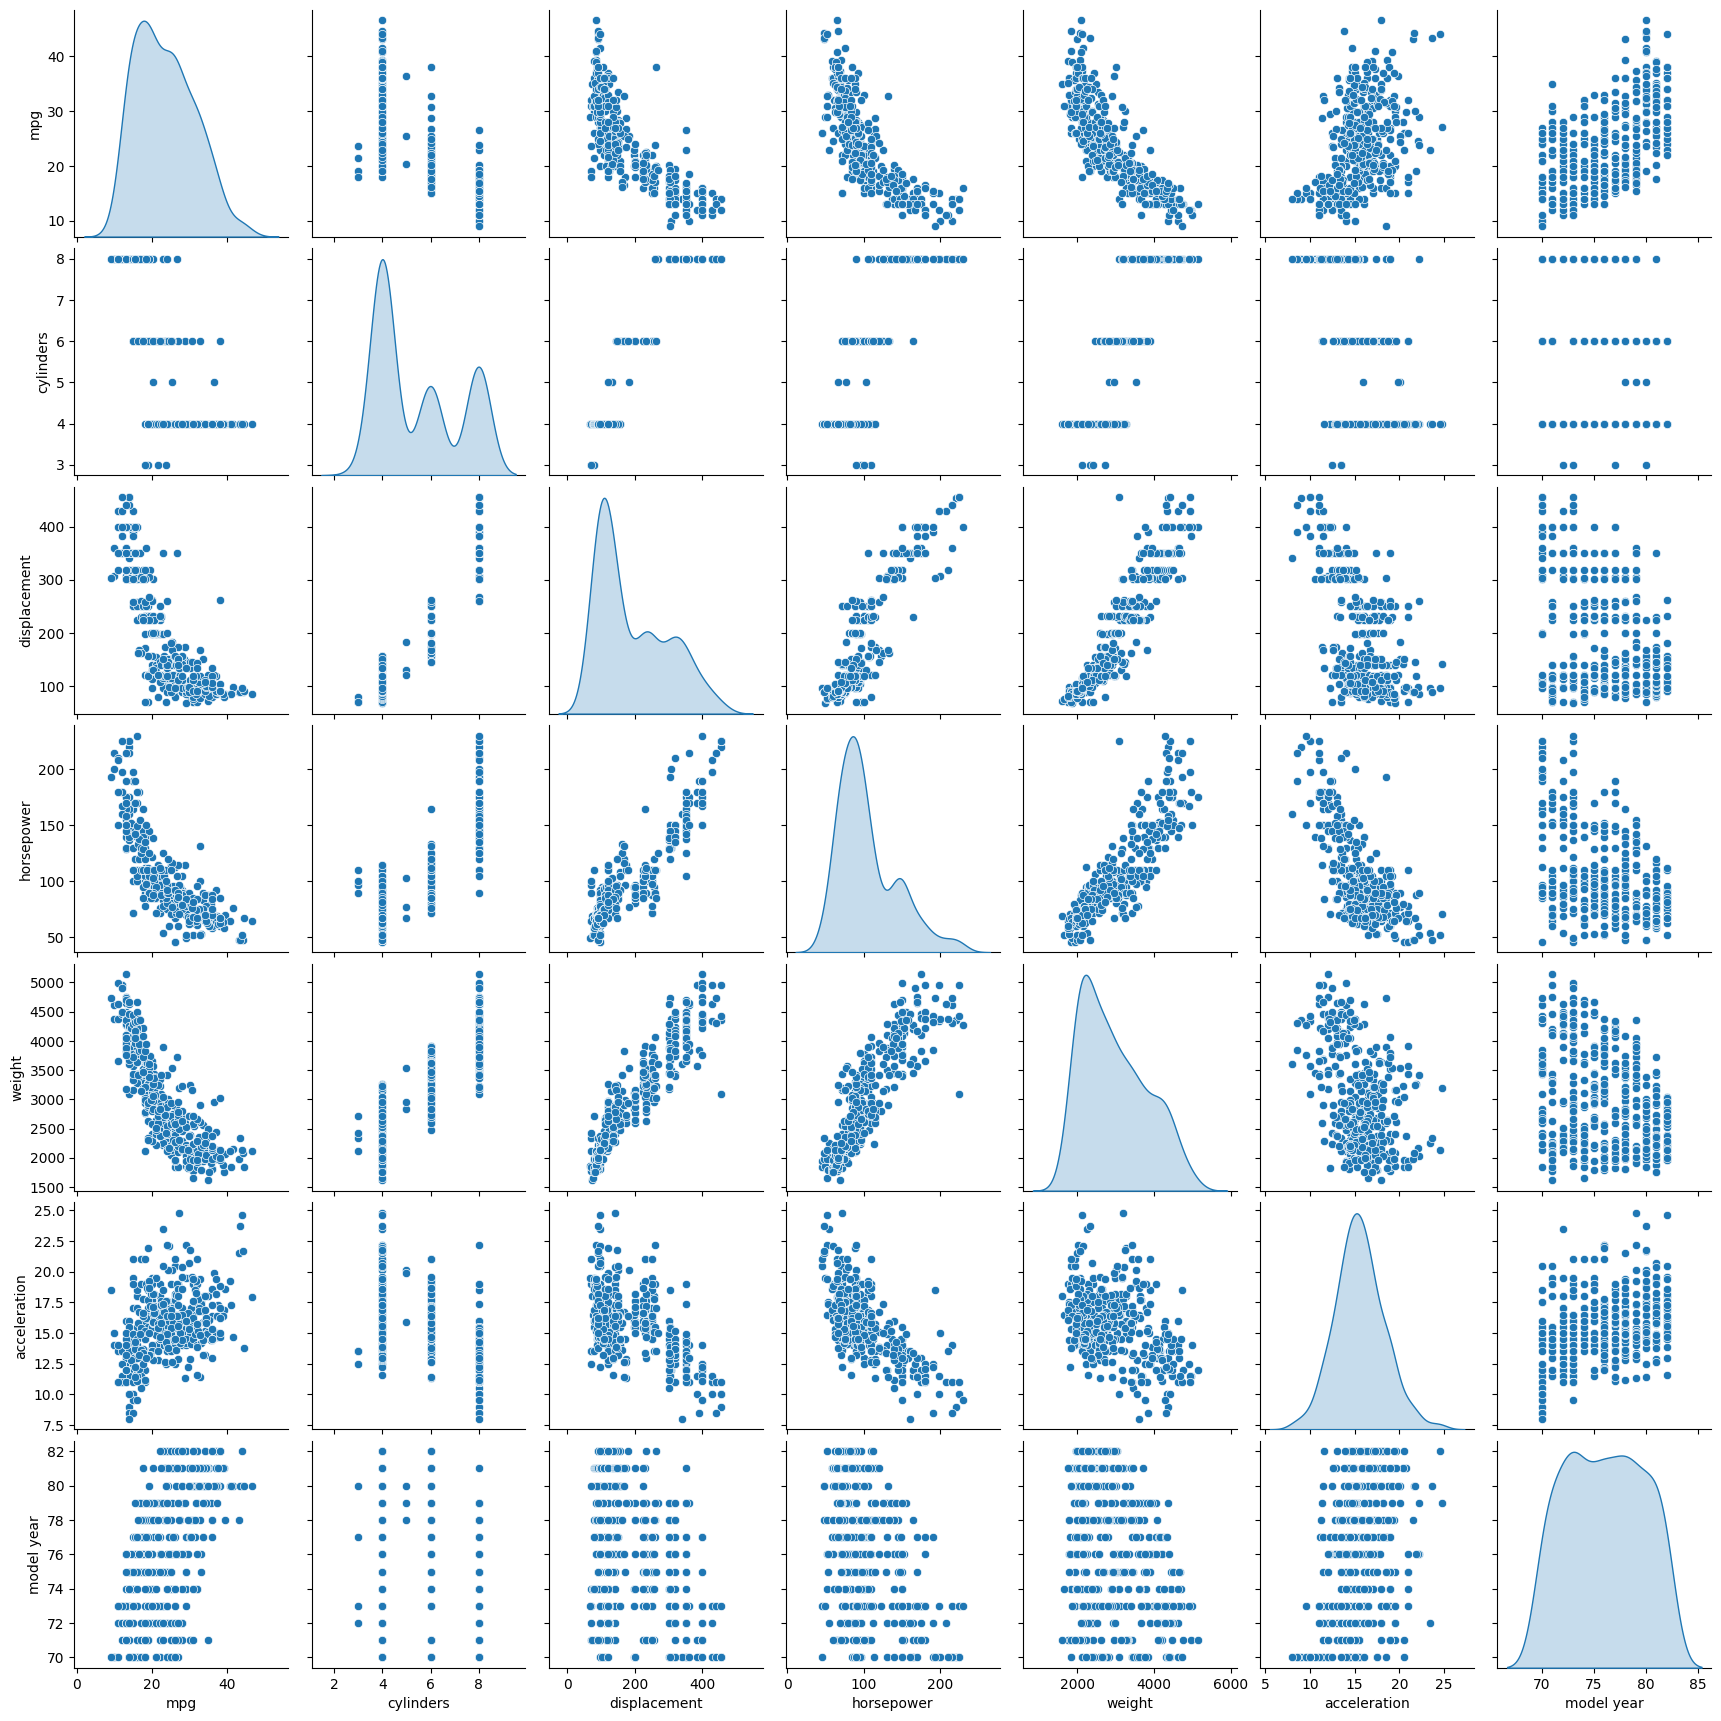

In [21]:
rdata_attr = rdata.iloc[:, 0:7]
sns.pairplot(rdata_attr, diag_kind='kde')

MPG Distribution

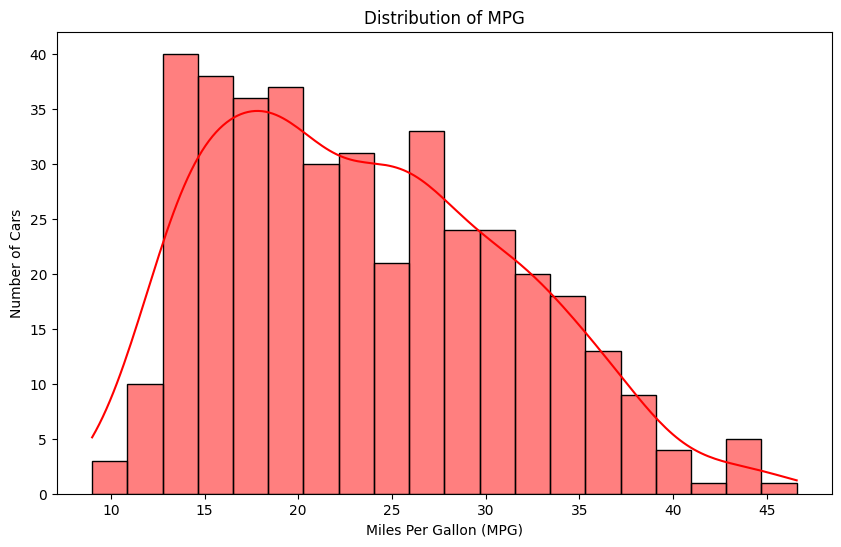

In [23]:
plt.figure(figsize=(10,6))

sns.histplot(data=rdata, x="mpg", bins=20, kde=True , color = "r")

plt.title("Distribution of MPG")
plt.xlabel("Miles Per Gallon (MPG)")
plt.ylabel("Number of Cars")

plt.show()

Cylinders Distribution

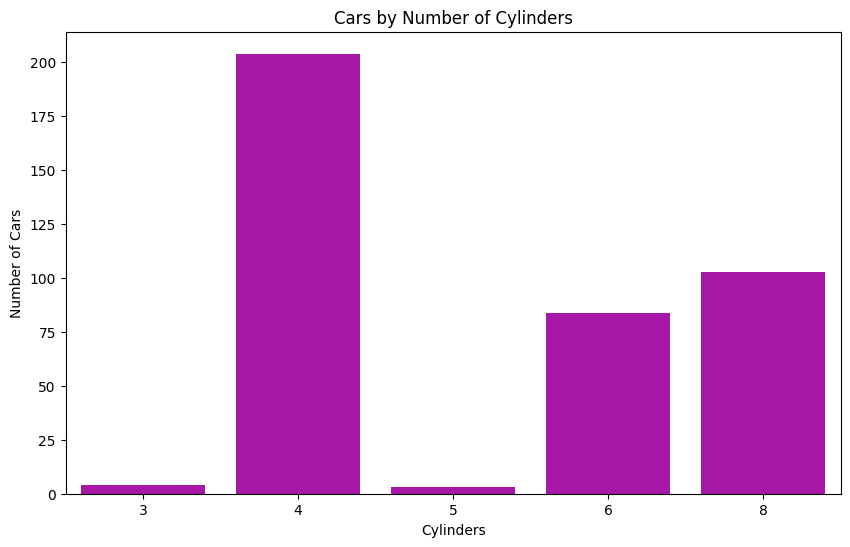

In [24]:
plt.figure(figsize=(10,6))

sns.countplot(data=rdata, x="cylinders" , color = "m")

plt.title("Cars by Number of Cylinders")
plt.xlabel("Cylinders")
plt.ylabel("Number of Cars")

plt.show()

Horsepower Distribution

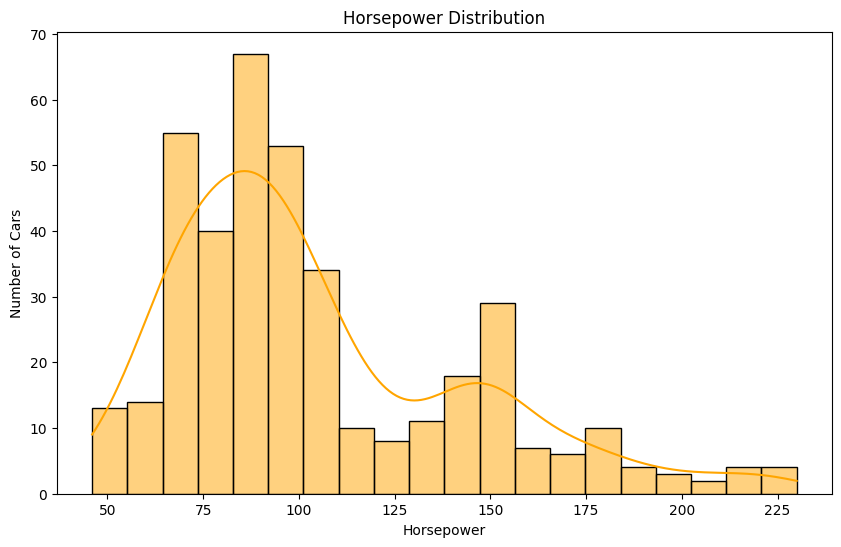

In [25]:
plt.figure(figsize=(10,6))

sns.histplot(data=rdata, x="horsepower", bins=20, kde=True , color = "orange")

plt.title("Horsepower Distribution")
plt.xlabel("Horsepower")
plt.ylabel("Number of Cars")

plt.show()

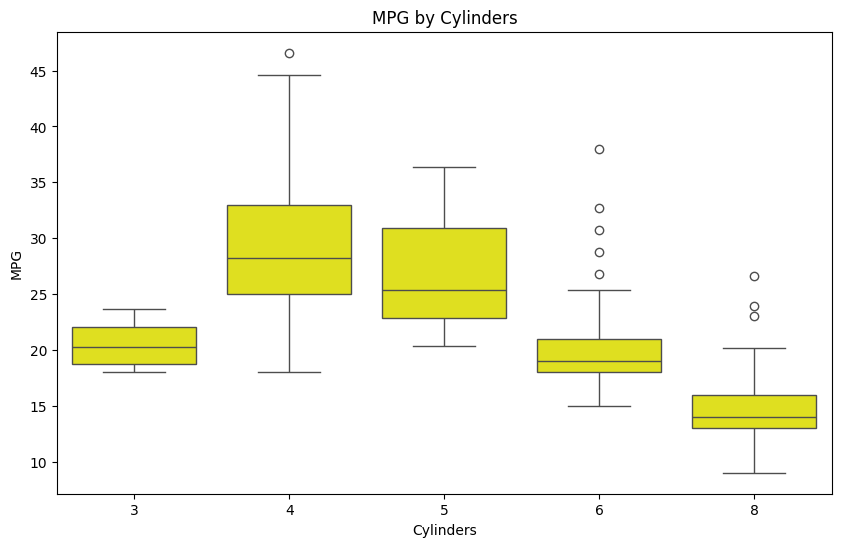

In [26]:
#MPG by Cylinders
plt.figure(figsize=(10,6))

sns.boxplot(data=rdata, x="cylinders", y="mpg", color = "yellow")

plt.title("MPG by Cylinders")
plt.xlabel("Cylinders")
plt.ylabel("MPG")

plt.show()

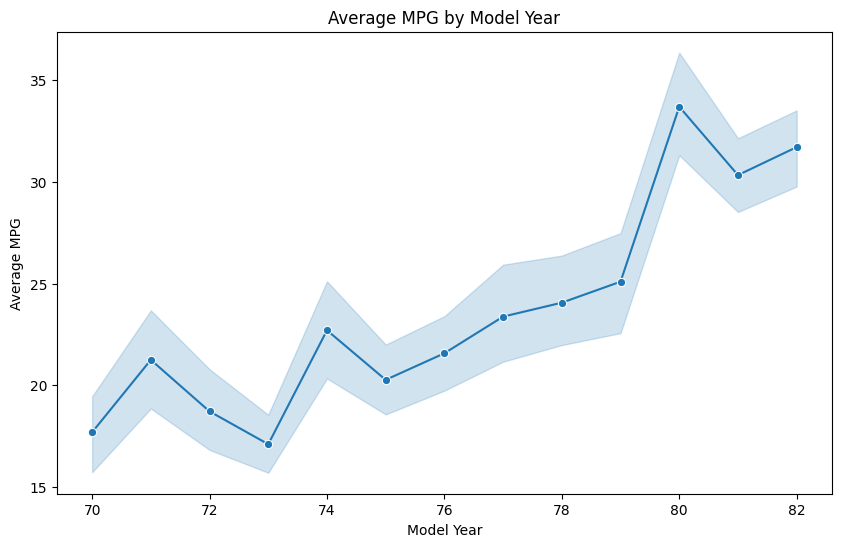

In [27]:
#Year-wise Average MPG
plt.figure(figsize=(10,6))

sns.lineplot(data=rdata,x="model year", y="mpg",estimator="mean",marker="o")

plt.title("Average MPG by Model Year")
plt.xlabel("Model Year")
plt.ylabel("Average MPG")

plt.show()

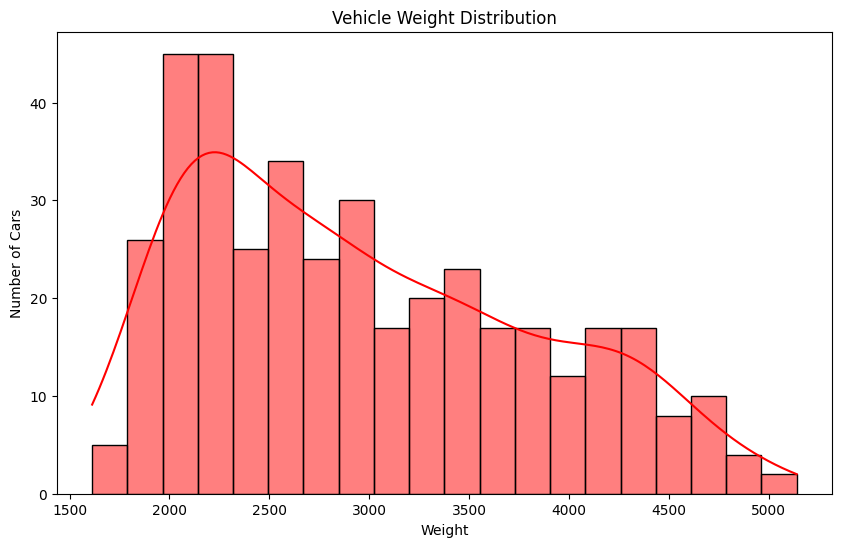

In [28]:
#Weight Distribution
plt.figure(figsize=(10,6))

sns.histplot(data=rdata, x="weight", bins=20, kde=True, color = "red")

plt.title("Vehicle Weight Distribution")
plt.xlabel("Weight")
plt.ylabel("Number of Cars")

plt.show()

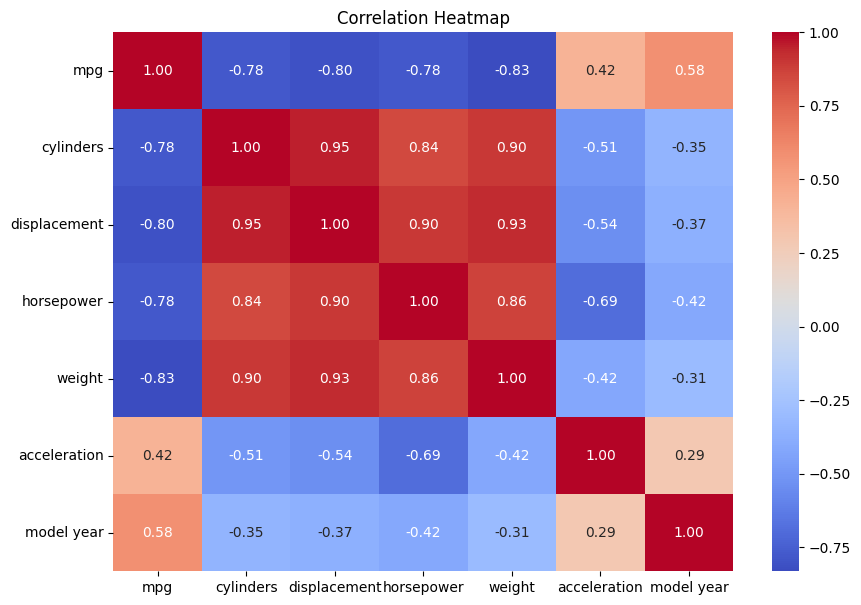

In [29]:
#Correlation Heatmap
plt.figure(figsize=(10,7))

numeric_df = rdata.select_dtypes(include="number")

sns.heatmap(numeric_df.corr(),annot=True,cmap="coolwarm",fmt=".2f")

plt.title("Correlation Heatmap")

plt.show()

# Splitting the Data and creating out model

In [30]:
# independant variables
X = rdata.drop(['mpg','origin_europe'], axis=1)
# the dependent variable
y = rdata[['mpg']]

In [31]:
# # Split X and y into training and test set in 70:30 ratio
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.30, random_state=1)

In [34]:
regression_model = LinearRegression()
regression_model.fit(X_train, y_train)

LinearRegression()

In [35]:
#Coefficients
for idx, col_name in enumerate(X_train.columns):
    print("The coefficient for {} is {}".format(col_name, regression_model.coef_[0][idx]))

The coefficient for cylinders is -0.3944081227884508
The coefficient for displacement is 0.028963633622016916
The coefficient for horsepower is -0.021882409531881097
The coefficient for weight is -0.007348752653540333
The coefficient for acceleration is 0.06120911112060382
The coefficient for model year is 0.8367951258668047
The coefficient for origin_america is -3.0041953503269347
The coefficient for origin_asia is -0.6041008524693456


In [36]:
#Intercept
intercept = regression_model.intercept_[0]
print("The intercept for our model is {}".format(intercept))

The intercept for our model is -18.26356210639761


In [37]:
#Training R²
regression_model.score(X_train, y_train)

0.8141032889112416

In [39]:
#Adding interaction terms
from sklearn.preprocessing import PolynomialFeatures
from sklearn import linear_model

poly = PolynomialFeatures(degree=2, interaction_only=True)
X_train2 = poly.fit_transform(X_train)
X_test2 = poly.fit_transform(X_test)

# fit linear model

poly_clf = linear_model.LinearRegression()
poly_clf.fit(X_train2, y_train)

y_pred = poly_clf.predict(X_test2)
print(y_pred)

[[22.09855915]
 [29.83672453]
 [17.29623112]
 [23.74404505]
 [23.12744502]
 [15.88360514]
 [32.82508876]
 [37.28107098]
 [17.64678994]
 [13.15995428]
 [30.66410369]
 [18.86966075]
 [20.25730296]
 [25.11786215]
 [40.71412778]
 [21.38337559]
 [13.55593028]
 [19.87502332]
 [13.52827521]
 [35.50388265]
 [22.8352029 ]
 [32.32425417]
 [19.92836848]
 [24.2559287 ]
 [22.43570809]
 [30.64899776]
 [33.20601551]
 [35.08695894]
 [16.33583281]
 [30.83736764]
 [23.52584199]
 [14.66296023]
 [18.8094778 ]
 [26.44095102]
 [24.70458175]
 [13.2897373 ]
 [27.46069582]
 [13.3366707 ]
 [34.39752546]
 [23.61573641]
 [26.44729622]
 [24.48753232]
 [18.51897647]
 [34.19684094]
 [23.58542659]
 [21.05360952]
 [18.7660262 ]
 [13.90485528]
 [27.60383818]
 [17.79488992]
 [23.27904137]
 [26.16506998]
 [16.64601616]
 [13.84172763]
 [30.38358045]
 [23.04144397]
 [13.1882156 ]
 [13.59637969]
 [31.322015  ]
 [38.27896251]
 [37.63910286]
 [38.61145903]
 [16.49390466]
 [24.2999787 ]
 [17.66741977]
 [33.76565834]
 [24.39738

In [40]:
#Training R²
print(poly_clf.score(X_train2, y_train))

0.9025447994413608


In [41]:
#Out off sample (testing) R^2 is our measure of sucess and does improve
print(poly_clf.score(X_test2, y_test))

0.8671169293382763


In [42]:
print(X_train.shape)
print(X_train2.shape)

(278, 8)
(278, 37)
